In [12]:
import os
import glob
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, Input, mixed_precision
from sklearn.model_selection import train_test_split
import cv2
import keras
print("library loaded successfully")
print("*"*100)


library loaded successfully
****************************************************************************************************


In [6]:
%matplotlib inline

import os
import cv2
import gc
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler
@tf.keras.utils.register_keras_serializable()
class KerasPCCLayer(layers.Layer):
    """Natively computes spatial Pearson Correlation Coefficients within the network graph."""
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)

    def call(self, inputs):
        # We used epsilon sothat standard deviation value cannot be zero, otherwise code will crash
        epsilon = 1e-8
        # finds the average standard deviaiton
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        # data normalization or (Z-Score)
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1))
        return layers.Flatten()(pcc_matrix)
@keras.saving.register_keras_serializable()
def dice_coef(y_true, y_pred, smooth=1.0):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)
def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)
def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + dice_loss(y_true, y_pred)
def focal_tversky_loss(y_true, y_pred, alpha=0.7, beta=0.3, gamma=0.75):
    """
    Focal Tversky Loss for imbalanced medical image segmentation.
    alpha: controls penalty for False Negatives (FN) -> keeping it higher (0.7) focuses on small polyps.
    beta: controls penalty for False Positives (FP).
    """
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    # Calculate True Positives, False Negatives, and False Positives
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    
    # Tversky Index
    smooth = 1e-6
    tversky_index = (tp + smooth) / (tp + alpha * fn + beta * fp + smooth)
    
    # Focal Tversky Loss
    return tf.math.pow((1.0 - tversky_index), gamma)
@keras.saving.register_keras_serializable()
def iou_metric(y_true, y_pred):
    y_true_f = tf.cast(y_true, tf.float32)
    y_pred_f = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + 1.0) / (union + 1.0)
@keras.saving.register_keras_serializable()
def tnr_metric(y_true, y_pred):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)

    true_negatives = tf.reduce_sum(tf.cast((1.0 - y_true_f) * (1.0 - y_pred_f), tf.float32))
    false_positives = tf.reduce_sum(tf.cast((1.0 - y_true_f) * y_pred_f, tf.float32))
    
    # TNR = TN / (TN + FP)
    return (true_negatives + 1e-7) / (true_negatives + false_positives + 1e-7)
@keras.saving.register_keras_serializable()
def mean_iou_metric(y_true, y_pred):
    # Flatten the matrices to 1D tensors to calculate pixel-level metrics
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    # Apply hard thresholding (Same as your F2 and Dice implementation)
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    
    # Calculate basic confusion matrix components for the positive class (Polyp)
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))
    
    # Calculate True Negatives (TN) which represents correctly classified background pixels
    tn = tf.reduce_sum((1.0 - y_true_f) * (1.0 - y_pred_f))

    # ─── 🎯 STEP 1: CALCULATE IoU FOR POLYP CLASS (Positive Class) ───
    polyp_iou = (tp + 1e-7) / (tp + fp + fn + 1e-7)
    
    # ─── 🌍 STEP 2: CALCULATE IoU FOR BACKGROUND CLASS (Negative Class) ───
    # For background: TN is True Positive, FN becomes False Positive, and FP becomes False Negative
    bg_iou = (tn + 1e-7) / (tn + fn + fp + 1e-7)
    
    # ─── 📊 STEP 3: COMPUTE THE MEAN (AVERAGE) IoU OF BOTH CLASSES ───
    mIoU = (polyp_iou + bg_iou) / 2.0
    
    return mIoU
@keras.saving.register_keras_serializable()
def f2_segmentation(y_true, y_pred):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))

    numerator = 5.0 * tp + 1e-7
    denominator = 5.0 * tp + 4.0 * fn + fp + 1e-7
    
    return numerator / denominator
@keras.saving.register_keras_serializable()
def precision_segmentation(y_true, y_pred):
    # Flatten the matrices to 1D tensors to calculate pixel-level metrics
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    # Apply hard thresholding (Same as your F2 and mIoU implementation)
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    
    # Calculate True Positives (TP) and False Positives (FP)
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    
    # Precision Formula: TP / (TP + FP)
    # Adding a tiny epsilon (1e-7) to completely avoid zero division errors
    numerator = tp + 1e-7
    denominator = tp + fp + 1e-7
    
    return numerator / denominator
# ─────────────────────────────────────────────────────────────────────────────
# ⚙️ GLOBAL INFERENCE CONFIGURATIONS & ELM ARTIFACTS LINKING
# ─────────────────────────────────────────────────────────────────────────────
IMG_SIZE = 256

class NumpyFeatureSelector:
    """Stand-in for sklearn's SelectKBest at inference time — all we need is
    the column indices it kept, not the fitted statistics."""
    def __init__(self, indices):
        self.indices = np.asarray(indices, dtype=np.int32)

    def transform(self, X):
        return X[:, self.indices]


def load_elm_artifacts(path):
    data = np.load(path)
    ensemble_weights = [data['ensemble_weights'][i] for i in range(data['ensemble_weights'].shape[0])]

    scaler = RobustScaler()
    scaler.center_ = data['scaler_center_']
    scaler.scale_ = data['scaler_scale_']
    scaler.n_features_in_ = scaler.center_.shape[0]

    selector = NumpyFeatureSelector(data['selector_support'])

    return data['W_input'], data['b_input'], ensemble_weights, scaler, selector

# Prefer whatever is already in this notebook's memory (e.g. you just ran the
# training script in this same session). Otherwise fall back to the saved
# .npz file on disk, so you never have to re-run training just to test.
try:
    GLOBAL_W_input = W_input
    GLOBAL_b_input = b_input
    GLOBAL_ensemble_weights = ensemble_weights
    GLOBAL_scaler = scaler
    GLOBAL_selector = selector
    print("✅ [ELM LINK LOCKED] Using ELM engine already in memory (this session's training run).")
except NameError:
    if os.path.exists(ELM_ARTIFACT_PATH):
        print(f"⏳ ELM engine not found in memory — loading saved artifacts from: {ELM_ARTIFACT_PATH}")
        GLOBAL_W_input, GLOBAL_b_input, GLOBAL_ensemble_weights, GLOBAL_scaler, GLOBAL_selector = load_elm_artifacts(ELM_ARTIFACT_PATH)
        print("✅ [ELM LINK LOCKED] Successfully loaded the saved Ensemble ELM Engine & Selector from disk!")
    else:
        raise RuntimeError(
            f"❌ [CRITICAL] No ELM weights in memory and no saved artifacts found at:\n"
            f"    {ELM_ARTIFACT_PATH}\n"
            f"Run the ELM training script once (it now saves this file automatically) — after that "
            f"you only need this inference script."
        )
# ─────────────────────────────────────────────────────────────────────────────
# 🎨 REFINED IMAGE LABELED LOCALIZATION ENGINE
# ─────────────────────────────────────────────────────────────────────────────
def draw_bounding_box(image, mask):
    res_img = image.copy()
    mask_uint8 = (mask > 0.5).astype(np.uint8) * 255
    contours, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    pixel_to_cm_ratio = 50

    for cnt in contours:
        if cv2.contourArea(cnt) < 10:
            continue

        x, y, w, h = cv2.boundingRect(cnt)
        width_cm = w / pixel_to_cm_ratio
        height_cm = h / pixel_to_cm_ratio
        size_text = f"Polyp: {width_cm:.1f}cm x {height_cm:.1f}cm"


        cv2.rectangle(res_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
        text_y = y - 10 if y - 10 > 20 else y + h + 20


        cv2.putText(res_img, size_text, (x + 1, text_y + 1),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 2, cv2.LINE_AA)

        cv2.putText(res_img, size_text, (x, text_y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1, cv2.LINE_AA)

    return res_img

# ─────────────────────────────────────────────────────────────────────────────
# 🔮 MULTI-TASK INFERENCE CORE PIPELINE (FIXED FOR SELECTION & SCALING)
# ─────────────────────────────────────────────────────────────────────────────
def test_and_display(model, feature_extractor, image_path, optimal_threshold=0.47, output_filename='result.png'):
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"❌ Target frame could not be loaded at: {image_path}")
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
    lab = cv2.cvtColor(img_res, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l_channel)
    limg = cv2.merge((cl, a_channel, b_channel))
    enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    median_blur = cv2.medianBlur(enhanced_img, 3)
    sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)

    inp = np.expand_dims(sharpened / 255.0, axis=0).astype(np.float32)


    pred_outputs = model.predict(inp, verbose=0)
    pred_mask_spatial = pred_outputs[0][0]

    feats = feature_extractor(inp, training=False)
    feats_flat = tf.reshape(feats, [tf.shape(feats)[0], -1]).numpy().flatten().reshape(1, -1).astype(np.float32)

    feats_selected = GLOBAL_selector.transform(feats_flat).astype(np.float32)


    feats_scaled = GLOBAL_scaler.transform(feats_selected).astype(np.float32)

    H_inst = np.tanh(np.dot(feats_scaled, GLOBAL_W_input) + GLOBAL_b_input)


    all_raw = []
    for W_out in GLOBAL_ensemble_weights:
        raw = np.dot(H_inst, W_out)
        all_raw.append(raw)

    final_score = np.mean(all_raw)

    clf_probability = 1 / (1 + np.exp(-final_score))


    mask_bin = (pred_mask_spatial > 0.5).astype(np.uint8)
    mask_3d = np.concatenate([mask_bin] * 3, axis=-1)
    extracted = (img_res * mask_3d).astype(np.uint8)
    detected_img = draw_bounding_box(img_res, pred_mask_spatial)


    if clf_probability >= optimal_threshold:
        diagnostic_text = f"DIAGNOSIS: POLYP DETECTED ({clf_probability * 100:.2f}% Match Score)"
        title_color = '#1faa00' # Vibrant Green
    else:
        diagnostic_text = f"DIAGNOSIS: NON-POLYP ({(1.0 - clf_probability) * 100:.2f}% Clean Score)"
        title_color = '#dd0000' # Deep Red


    titles = ['(a) Original Frame', '(b) Predicted Mask', '(c) Extracted Region', '(d) Localization View']
    display_images = [img_res, pred_mask_spatial.squeeze(), extracted, detected_img]

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    for i in range(4):
        axes[i].imshow(display_images[i], cmap='gray' if i == 1 else None)
        axes[i].set_title(titles[i], fontsize=13, fontweight='bold', pad=12)
        axes[i].axis('off')

    plt.suptitle(diagnostic_text, fontsize=16, fontweight='bold', color=title_color, y=1.04)
    plt.tight_layout()

    plt.savefig(output_filename, dpi=300, bbox_inches='tight')
    print(f"🏆 [ELM SUCCESS] Qualitative evaluation plot saved to: {output_filename}")
    plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# 🏃‍♂️ EXECUTION PIPELINE LOOP
# ─────────────────────────────────────────────────────────────────────────────

⏳ ELM engine not found in memory — loading saved artifacts from: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/elm_artifacts.npz
✅ [ELM LINK LOCKED] Successfully loaded the saved Ensemble ELM Engine & Selector from disk!


⏳ Loading Keras Architecture Graph & Setting Cut-off point...
✅ Multi-Task Graph integrated with ELM Input Pipeline at layer 'clf_pcc_layer'.

🎬 Processing Positive Dataset Specimen 1...


I0000 00:00:1784973315.155309    5293 service.cc:153] XLA service 0x719c3005a850 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1784973315.155377    5293 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.7.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1784973315.274904    5293 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
E0000 00:00:1784973326.743039    5293 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1784973332.990082    5293 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1784973345.946410    5293 device_compiler.h:208] Compiled cluster using

🏆 [ELM SUCCESS] Qualitative evaluation plot saved to: thesis_positive_result.png


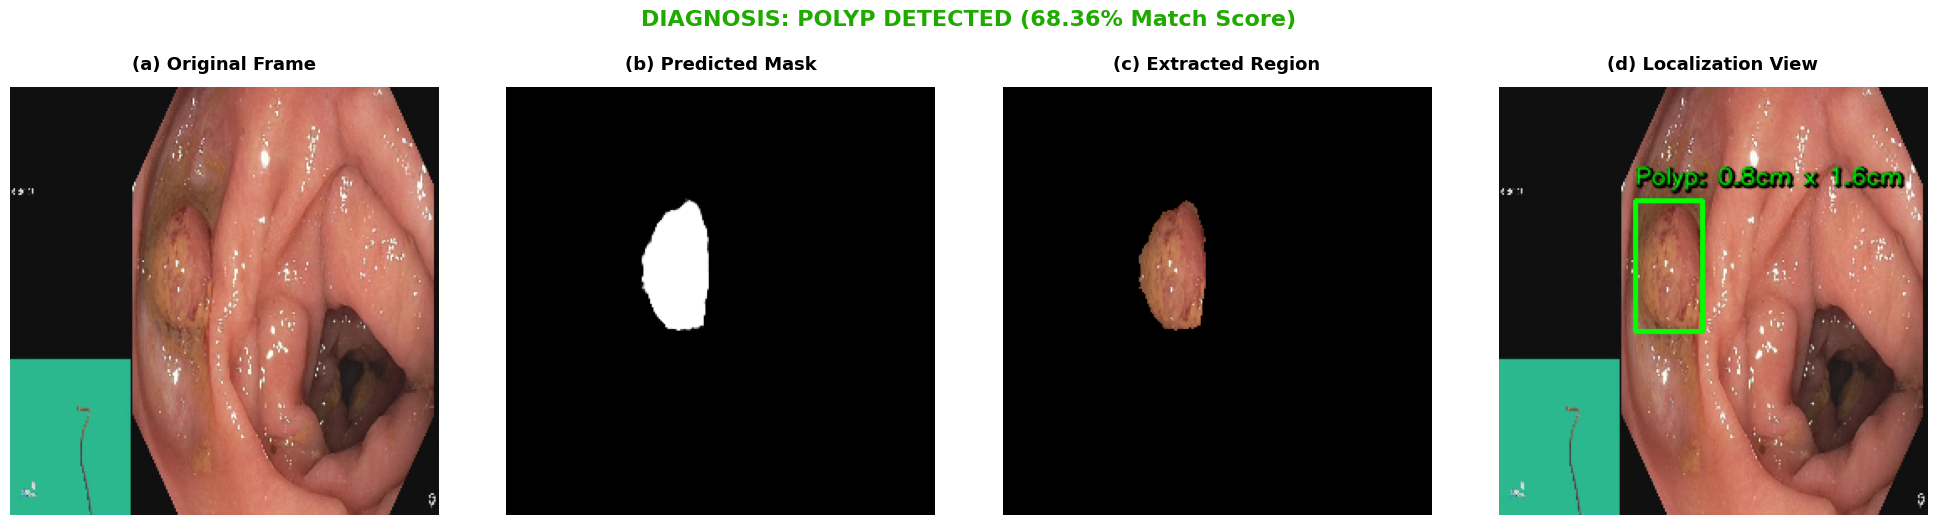

In [7]:
def detect_polyp_function(ELM_ARTIFACT_PATH, MODEL_PATH, TEST_POSITIVE_IMAGE_PATH):
    print("⏳ Loading Keras Architecture Graph & Setting Cut-off point...")
    shared_model = tf.keras.models.load_model(MODEL_PATH, compile=False)
    try:
        target_layer = 'clf_pcc_layer'
        _ = shared_model.get_layer(target_layer)
    except Exception:
        target_layer = 'clf_gap'
    inference_extractor = tf.keras.Model(inputs=shared_model.input, outputs=shared_model.get_layer(target_layer).output)
    print(f"✅ Multi-Task Graph integrated with ELM Input Pipeline at layer '{target_layer}'.\n")
    VAL_BEST_THRESH = 0.60
    print("🎬 Processing Positive Dataset Specimen 1...")
    test_and_display(shared_model, inference_extractor, TEST_POSITIVE_IMAGE_PATH, VAL_BEST_THRESH, 'thesis_positive_result.png')
ELM_ARTIFACT_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/elm_artifacts.npz"
MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
TEST_POSITIVE_IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/images_C4/16_endocv2021_positive_557.jpg"
detect_polyp_function(ELM_ARTIFACT_PATH, MODEL_PATH, TEST_POSITIVE_IMAGE_PATH)

# Occulation Sencitivity

In [3]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

@tf.keras.utils.register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)
        
    def call(self, inputs):
        batch_size = tf.shape(inputs)[0]
        return tf.zeros((batch_size, 1024), dtype=inputs.dtype)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], 1024)

    def get_config(self):
        return super(KerasPCCLayer, self).get_config()

def analyze_occlusion_sensitivity(image_path, model_path, output_dir="./occlusion_output", img_size=256, patch_size=32, stride=16):
    """
    Loads a model and an image, computes the occlusion sensitivity map, 
    displays the result, and saves it to the output directory.
    """
    
    # 1. Setup output directory
    os.makedirs(output_dir, exist_ok=True)
    
    # 2. Load the model
    print("⏳ Loading trained model safely...")
    try:
        model = tf.keras.models.load_model(
            model_path, 
            custom_objects={'KerasPCCLayer': KerasPCCLayer}, 
            compile=False
        )
    except Exception as e:
        print(f"⚠️ Error loading model: {e}")
        return
        
    # 3. Read and preprocess image
    if not os.path.exists(image_path):
        print(f"⚠️ Error: Image file missing at: {image_path}")
        return
        
    raw_bgr = cv2.imread(image_path)
    if raw_bgr is None:
        print(f"⚠️ Error: OpenCV could not read the image at: {image_path}")
        return
        
    orig_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    resized_rgb = cv2.resize(orig_rgb, (img_size, img_size))
    normalized_tensor = np.expand_dims(resized_rgb / 255.0, axis=0)
    
    # 4. Compute Occlusion Sensitivity
    print("🧠 Computing Occlusion Sensitivity Map (this may take a moment)...")
    raw_img = normalized_tensor[0]
    h, w, _ = raw_img.shape
    
    base_preds = model(normalized_tensor, training=False)
    base_mask = base_preds[0][0].numpy() if isinstance(base_preds, (list, tuple)) else base_preds[0].numpy()
    base_score = np.mean(base_mask)
    
    sensitivity_map = np.zeros((h, w), dtype=np.float32)
    heatmap_overlap_counts = np.zeros((h, w), dtype=np.float32)

    for y in range(0, h - patch_size + 1, stride):
        for x in range(0, w - patch_size + 1, stride):
            masked_img = np.copy(raw_img)
            masked_img[y:y+patch_size, x:x+patch_size, :] = 0.5
            masked_tensor = np.expand_dims(masked_img, axis=0)
            
            occluded_preds = model(masked_tensor, training=False)
            occluded_mask = occluded_preds[0][0].numpy() if isinstance(occluded_preds, (list, tuple)) else occluded_preds[0].numpy()
            occluded_score = np.mean(occluded_mask)
            
            score_drop = max(0, base_score - occluded_score)
            sensitivity_map[y:y+patch_size, x:x+patch_size] += score_drop
            heatmap_overlap_counts[y:y+patch_size, x:x+patch_size] += 1.0

    # Normalize Map
    heatmap_overlap_counts[heatmap_overlap_counts == 0] = 1.0
    sensitivity_map /= heatmap_overlap_counts
    
    map_min, map_max = sensitivity_map.min(), sensitivity_map.max()
    if map_max - map_min > 1e-5:
        sensitivity_map = (sensitivity_map - map_min) / (map_max - map_min)
        
    # 5. Visualization & Saving
    heatmap = cv2.applyColorMap(np.uint8(255 * sensitivity_map), cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay_img = cv2.addWeighted(resized_rgb, 0.6, heatmap_rgb, 0.4, 0)
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    axes[0].imshow(resized_rgb)
    axes[0].set_title("Original Image", fontsize=12)
    axes[0].axis("off")
    
    axes[1].imshow(sensitivity_map, cmap="jet")
    axes[1].set_title("Occlusion Heatmap", fontsize=12)
    axes[1].axis("off")
    
    axes[2].imshow(overlay_img)
    axes[2].set_title("Explanatory Occlusion Overlay", fontsize=12)
    axes[2].axis("off")
    
    plt.tight_layout()
    
    # Save target visualizations directly to local directory
    filename = os.path.basename(image_path).split('.')[0] + "_occlusion.png"
    output_path = os.path.join(output_dir, filename)
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"🏆 Visualization compiled and saved cleanly at: {output_path}")
    return output_path

In [ ]:
import os
import cv2
import numpy as np
import tensorflow as tf
import shap
import matplotlib.pyplot as plt

# ==============================================================================
# ১. কাস্টম লেয়ার (গ্লোবালি রাখা হলো যাতে Keras মডেল লোড করার সময় এটি সহজেই পায়)
# ==============================================================================
@tf.keras.utils.register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)
        
    def call(self, inputs):
        epsilon = 1e-8
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1))
        return tf.keras.layers.Flatten()(pcc_matrix)
        
    def get_config(self):
        return super().get_config()


# ==============================================================================
# ২. মূল SHAP ফাংশন
# ==============================================================================
def generate_shap_explanation(
    image_path, 
    model_path, 
    elm_artifact_path, 
    output_png="shap_image_explanation.png", 
    img_size=(256, 256), 
    max_evals=300, 
    batch_size=32
):
    """
    Keras + ELM Ensemble মডেল দিয়ে কোনো ইমেজের SHAP explanation জেনারেট করার ফাংশন।
    
    রিটার্ন করবে: (prediction_probability, shap_values)
    """
    
    # ইনপুট ফাইলগুলো আছে কিনা চেক করা
    if not os.path.exists(model_path):
        raise FileNotFoundError(f"মডেল ফাইল পাওয়া যায়নি: {model_path}")
    if not os.path.exists(elm_artifact_path):
        raise FileNotFoundError(f"ELM artifact ফাইল পাওয়া যায়নি: {elm_artifact_path}")
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"ইমেজ ফাইল পাওয়া যায়নি: {image_path}")

    print("⏳ Loading model and ELM artifacts...")
    
    # 2.1 মডেল এবং ফিচার এক্সট্রাক্টর লোড করা
    model = tf.keras.models.load_model(model_path, custom_objects={'KerasPCCLayer': KerasPCCLayer}, compile=False)
    feature_extractor = tf.keras.Model(inputs=model.input, outputs=model.get_layer('clf_pcc_layer').output)

    # 2.2 ELM artifacts লোড করা
    elm = np.load(elm_artifact_path, allow_pickle=True)
    selector_support = elm['selector_support']          
    scaler_center = elm['scaler_center_']                
    scaler_scale = elm['scaler_scale_']                  
    W_input_all = elm['W_input']
    b_input_all = elm['b_input']
    W_out_all = elm['ensemble_weights']

    # 2.3 ইনডেক্স বের করা
    if selector_support.dtype == bool:
        selected_indices = np.where(selector_support)[0]
    else:
        selected_indices = selector_support.astype(int)

    assert W_input_all.shape[0] == len(selected_indices), (
        f"W_input এর সারি সংখ্যা ({W_input_all.shape[0]}) selected feature সংখ্যার ({len(selected_indices)}) "
        "সাথে মেলেনি — selector_support ঠিকভাবে পার্স হয়েছে কিনা যাচাই করুন।"
    )

    # 2.4 Ensemble ওয়েট তৈরি করা
    b_input_vec = b_input_all.reshape(1, -1)                   # (1, hidden)
    lambda_outputs = W_out_all.reshape(W_out_all.shape[0], -1, 1)    # (n_lambda, hidden, 1)
    ensemble = [(W_input_all, b_input_vec, w_out) for w_out in lambda_outputs]
    print(f"✅ শেয়ার্ড hidden projection (shape {W_input_all.shape}) + {len(ensemble)}টা ridge-lambda output লোড হয়েছে।")

    # 2.5 ফুল পাইপলাইন প্রেডিকশন ফাংশন (SHAP এর জন্য)
    def full_pipeline_predict(images_uint8):
        batch = images_uint8.astype(np.float32) / 255.0
        feats = feature_extractor(batch, training=False).numpy()
        feats_sel = feats[:, selected_indices]
        feats_scaled = (feats_sel - scaler_center) / scaler_scale

        scores = []
        for W_input, b_input, W_out in ensemble:
            H = np.tanh(np.dot(feats_scaled, W_input) + b_input)
            scores.append(np.dot(H, W_out))
        probs = np.mean(scores, axis=0).flatten()
        return probs

    # 2.6 ইমেজ প্রসেসিং
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"cv2 couldn't read the image: {image_path}")
    
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, img_size).astype(np.uint8)

    # 2.7 প্রেডিকশন
    pred = full_pipeline_predict(np.expand_dims(img, axis=0))[0]
    print(f"🔎 Predicted polyp probability for this image: {pred:.4f}")

    # 2.8 SHAP Explanation
    masker = shap.maskers.Image("blur(128,128)", img.shape)
    explainer = shap.Explainer(full_pipeline_predict, masker)

    print(f"🚀 Running SHAP image explanation (max_evals={max_evals})... this may take a bit.")
    shap_values = explainer(
        np.expand_dims(img, axis=0),
        max_evals=max_evals,
        batch_size=batch_size,
    )

    # 2.9 ভিজুয়ালাইজেশন ও সেভ
    shap.image_plot(shap_values, show=False)
    plt.savefig(output_png, dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"🖼️ Saved SHAP explanation plot to: {output_png}")
    
    return pred, shap_values

In [9]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# =====================================================================
# 🛠️ Custom Keras Layer 
# (Must remain outside the function for proper Keras registration)
# =====================================================================
@tf.keras.utils.register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)
        
    def call(self, inputs):
        """Dynamic padding vector matching the 1024 dense dimension constraint."""
        batch_size = tf.shape(inputs)[0]
        return tf.zeros((batch_size, 1024), dtype=inputs.dtype)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], 1024)

    def get_config(self):
        return super(KerasPCCLayer, self).get_config()

# =====================================================================
# 🚀 Unified Single Function for Score-CAM
# =====================================================================
def analyze_score_cam(image_path, model_path, output_dir="./score_cam_output", img_size=256, max_n_features=32):
    """
    Loads a model and an image, computes the Score-CAM visualization,
    displays the result, and saves it to the output directory.
    """
    
    # 1. Setup output directory
    os.makedirs(output_dir, exist_ok=True)
    
    # 2. Read and preprocess image first to catch path errors early
    if not os.path.exists(image_path):
        print(f"⚠️ Error: Image file missing at: {image_path}")
        return
        
    raw_bgr = cv2.imread(image_path)
    if raw_bgr is None:
        print(f"⚠️ Error: OpenCV could not read the image at: {image_path}")
        return
        
    orig_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    resized_rgb = cv2.resize(orig_rgb, (img_size, img_size))
    normalized_tensor = np.expand_dims(resized_rgb / 255.0, axis=0)

    # 3. Load the model safely
    print("⏳ Loading trained model for Score-CAM computation...")
    try:
        model = tf.keras.models.load_model(
            model_path, 
            custom_objects={'KerasPCCLayer': KerasPCCLayer}, 
            compile=False
        )
    except Exception as e:
        print(f"⚠️ Error loading model: {e}")
        return

    # 4. Automatically identify the deep target layer
    try:
        target_layer_name = [layer.name for layer in model.layers if isinstance(layer, (tf.keras.layers.Conv2D, tf.keras.layers.DepthwiseConv2D))][-1]
        print(f"🎯 Targeted Activation Layer: '{target_layer_name}'")
    except IndexError:
        print("⚠️ Error: Could not find any Conv2D or DepthwiseConv2D layer in the model.")
        return

    # 5. Create a sub-graph for Score-CAM extraction
    score_cam_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(target_layer_name).output, model.output]
    )

    # 6. Inner helper function for Score-CAM Algorithmic Implementation
    def generate_score_cam(img_tensor, cam_model, max_n_feats):
        features, predictions = cam_model(img_tensor, training=False)
        features = features[0].numpy() 
        
        # Extract base prediction safely
        if isinstance(predictions, (list, tuple)):
            base_prediction = predictions[0] 
        else:
            base_prediction = predictions
            
        h, w, c = features.shape
        cam = np.zeros((h, w), dtype=np.float32)
        channels_to_process = min(c, max_n_feats)
        
        for i in range(channels_to_process):
            feature_map = features[:, :, i]
            upsampled_map = cv2.resize(feature_map, (img_size, img_size))
            map_min, map_max = upsampled_map.min(), upsampled_map.max()
            if map_max - map_min > 1e-5:
                normalized_map = (upsampled_map - map_min) / (map_max - map_min)
            else:
                normalized_map = upsampled_map
            masked_input = img_tensor[0] * np.expand_dims(normalized_map, axis=-1)
            masked_input_tensor = np.expand_dims(masked_input, axis=0)
            g_pred = cam_model(masked_input_tensor, training=False)[1]
            if isinstance(g_pred, (list, tuple)):
                score = tf.reduce_mean(g_pred[0]).numpy() 
            else:
                score = tf.reduce_mean(g_pred).numpy()
                
            cam += score * feature_map

        cam = np.maximum(cam, 0)
        if cam.max() > 0:
            cam = cam / cam.max()
            
        return cv2.resize(cam, (img_size, img_size))

    # 7. Calculate Score-CAM activations map
    print("🧠 Computing Score-CAM Map (this may take a moment)...")
    score_cam_map = generate_score_cam(normalized_tensor, score_cam_model, max_n_features)
    
    # 8. Visualization Blending & Overlays
    heatmap = cv2.applyColorMap(np.uint8(255 * score_cam_map), cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay_img = cv2.addWeighted(resized_rgb, 0.6, heatmap_rgb, 0.4, 0)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(resized_rgb)
    axes[0].set_title("Original Image", fontsize=12)
    axes[0].axis("off")
    axes[1].imshow(score_cam_map, cmap="jet")
    axes[1].set_title("Raw Attention Map", fontsize=12)
    axes[1].axis("off")
    
    axes[2].imshow(overlay_img)
    axes[2].set_title("Score-CAM Overlay", fontsize=12)
    axes[2].axis("off")
    
    plt.tight_layout()
    
    # Save target visualizations
    filename = os.path.basename(image_path).split('.')[0] + "_score_cam.png"
    output_path = os.path.join(output_dir, filename)
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"🏆 Score-CAM visualization compiled and saved cleanly at: {output_path}")
    return output_path


In [29]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Notebook inside rendering configuration (For Jupyter)
%matplotlib inline

# ==============================================================================
# ১. কাস্টম লেয়ার (মডেল সঠিকভাবে লোড করার জন্য এটি অপরিহার্য)
# ==============================================================================
@tf.keras.utils.register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)
        
    def call(self, inputs):
        epsilon = 1e-8
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1))
        return tf.keras.layers.Flatten()(pcc_matrix)
        
    def get_config(self):
        return super().get_config()


# ==============================================================================
# ২. Feature Map Activation Engine (ফাংশন)
# ==============================================================================
def generate_feature_map(image_path, model_path, target_layer_name='clf_pd_cnn', output_dir="./feature_map_outputs", img_size=256):
    """
    একটি নির্দিষ্ট ইমেজের জন্য কনভোল্যুশনাল ফিচারের হিটম্যাপ জেনারেট করে।
    """
    
    # আউটপুট ডিরেক্টরি তৈরি
    os.makedirs(output_dir, exist_ok=True)
    
    # ইমেজ রিড করা
    orig_img = cv2.imread(image_path)
    if orig_img is None:
        print(f"⚠️ Error: Image could not be read from {image_path}")
        return None
        
    # মডেল লোড করা
    print("⏳ Loading model...")
    try:
        model = tf.keras.models.load_model(model_path, custom_objects={'KerasPCCLayer': KerasPCCLayer}, compile=False)
    except Exception as e:
        print(f"⚠️ Error loading model: {e}")
        return None

    # ১. Standard Preprocessing Pipeline
    img_rgb = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (img_size, img_size))
    
    lab = cv2.cvtColor(img_res, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l_channel)
    limg = cv2.merge((cl, a_channel, b_channel))
    enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    
    median_blur = cv2.medianBlur(enhanced_img, 3) 
    sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)
    inp = np.expand_dims(sharpened / 255.0, axis=0).astype(np.float32)

    # ২. Build a Forward Model slicing up to the Bottleneck Conv Layer
    try:
        feature_model = tf.keras.models.Model(inputs=model.input, outputs=model.get_layer(target_layer_name).output)
    except ValueError:
        print(f"⚠️ Error: Layer '{target_layer_name}' not found in the model.")
        return None

    # ৩. Extract the feature activations directly from forward pass
    features = feature_model(inp, training=False) 
    features = features[0].numpy() # Drop batch dimension 
    
    # সেফটি চেক: Heatmap শুধুমাত্র Spatial ডাইমেনশনে (H, W, C) কাজ করে।
    if len(features.shape) != 3:
        print(f"⚠️ Error: Layer '{target_layer_name}' output is not 3D spatial (H, W, C). Current shape is {features.shape}.")
        print("💡 Suggestion: Use a Convolutional layer like 'clf_pd_cnn' instead of flattened layers like 'clf_pcc_layer'.")
        return None

    # ৪. Core Mathematical Fusion: Average across all channels
    feature_heatmap = np.mean(features, axis=-1) 
    feature_heatmap = np.maximum(feature_heatmap, 0) # ReLU equivalent
    
    # Normalize securely to map into 0-255 spectrum
    max_val = np.max(feature_heatmap)
    if max_val > 0:
        # Dynamic noise gate: wipe out minor activations below 10%
        feature_heatmap = np.where(feature_heatmap > (0.1 * max_val), feature_heatmap, 0.0)
        feature_heatmap = feature_heatmap / np.max(feature_heatmap)
    else:
        feature_heatmap = np.zeros_like(feature_heatmap)

    # ৫. Bilinear Upscaling to match target dimensions
    heatmap_resized = cv2.resize(feature_heatmap, (img_size, img_size))
    heatmap_u8 = np.uint8(255 * heatmap_resized)
    color_heatmap = cv2.applyColorMap(heatmap_u8, cv2.COLORMAP_JET)
    color_heatmap_rgb = cv2.cvtColor(color_heatmap, cv2.COLOR_BGR2RGB)
    
    # Overlay Blend: 60% original image + 40% Heatmap
    overlay_img = cv2.addWeighted(sharpened, 0.6, color_heatmap_rgb, 0.4, 0)

    # ৬. Plotting 3-Panel Verification Layout
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=130)
    plt.rcParams['font.family'] = 'sans-serif'
    
    axes[0].imshow(sharpened)
    axes[0].set_title("Input Image", fontsize=11, fontweight='bold')
    axes[0].axis('off')
    
    axes[1].imshow(heatmap_resized, cmap='jet')
    axes[1].set_title(f"Bottleneck Layer Feature Map\n({target_layer_name} Mean Activation)", fontsize=11, fontweight='bold')
    axes[1].axis('off')
    
    axes[2].imshow(overlay_img)
    axes[2].set_title("Feature Localization Overlay", fontsize=11, fontweight='bold')
    axes[2].axis('off')
    
    plt.tight_layout()
    
    img_id = os.path.splitext(os.path.basename(image_path))[0]
    output_filename = os.path.join(output_dir, f"feature_map_{img_id}.png")
    plt.savefig(output_filename, dpi=300, bbox_inches='tight')
    
    print(f"\n➔ [FORWARD TRACKING SUCCESS] Visualizing Frame ID: {img_id}")
    print(f"🖼️ Saved to: {output_filename}")
    
    plt.show()
    
    return output_filename

In [ ]:
import os
import cv2
import numpy as np
import tensorflow as tf
import shap
import matplotlib.pyplot as plt

# ==============================================================================
# ১. কাস্টম লেয়ার (মডেল লোড করার জন্য অপরিহার্য)
# ==============================================================================
@tf.keras.utils.register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)

    def call(self, inputs):
        epsilon = 1e-8
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1))
        return tf.keras.layers.Flatten()(pcc_matrix)

    def get_config(self):
        return super().get_config()


# ==============================================================================
# ২. ডাইরেক্ট ইমেজ থেকে SHAP Waterfall Plot জেনারেট করার ফাংশন
# ==============================================================================
def generate_waterfall_plot(
    image_path,
    model_path,
    elm_artifact_path,
    output_png="shap_waterfall.png",
    img_size=256,
    max_evals=500  # যদি পাস করেনও, কোড এটি নিজে অ্যাডজাস্ট করে নেবে
):


    # ফাইল চেক
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image not found: {image_path}")
    if not os.path.exists(model_path):
        raise FileNotFoundError(f"Model not found: {model_path}")
    if not os.path.exists(elm_artifact_path):
        raise FileNotFoundError(f"ELM artifact not found: {elm_artifact_path}")

    print("⏳ Loading model and ELM artifacts...")

    # মডেল এবং ফিচার এক্সট্রাক্টর লোড করা
    model = tf.keras.models.load_model(model_path, custom_objects={'KerasPCCLayer': KerasPCCLayer}, compile=False)
    feature_extractor = tf.keras.Model(inputs=model.input, outputs=model.get_layer('clf_pcc_layer').output)

    # ELM artifacts লোড করা
    elm = np.load(elm_artifact_path, allow_pickle=True)
    selector_support = elm['selector_support']
    scaler_center = elm['scaler_center_']
    scaler_scale = elm['scaler_scale_']
    W_input_all = elm['W_input']
    b_input_all = elm['b_input']
    W_out_all = elm['ensemble_weights']

    # ইনডেক্স প্রসেসিং
    if selector_support.dtype == bool:
        selected_indices = np.where(selector_support)[0]
    else:
        selected_indices = selector_support.astype(int)

    b_input_vec = b_input_all.reshape(1, -1)
    lambda_outputs = W_out_all.reshape(W_out_all.shape[0], -1, 1)
    ensemble = [(W_input_all, b_input_vec, w_out) for w_out in lambda_outputs]

    def elm_predict(feats_scaled):
        scores = []
        for W_input, b_input, W_out in ensemble:
            H = np.tanh(np.dot(feats_scaled, W_input) + b_input)
            scores.append(np.dot(H, W_out))
        return np.mean(scores, axis=0).flatten()

    # ইমেজ প্রিপ্রসেসিং
    orig_img = cv2.imread(image_path)
    if orig_img is None:
        raise ValueError(f"cv2 couldn't read image: {image_path}")

    img_rgb = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (img_size, img_size))

    lab = cv2.cvtColor(img_res, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l_channel)
    limg = cv2.merge((cl, a_channel, b_channel))
    enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

    median_blur = cv2.medianBlur(enhanced_img, 3)
    sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)
    inp = np.expand_dims(sharpened / 255.0, axis=0).astype(np.float32)

    # ফিচার এক্সট্রাকশন এবং স্কেলিং
    feats = feature_extractor(inp, training=False).numpy()
    feats_sel = feats[:, selected_indices]
    X_explain = (feats_sel - scaler_center) / scaler_scale  # Shape: (1, K)

    # ফিচার নেম তৈরি
    feature_names = [f"feat_{i}" for i in selected_indices]
    background_features = np.zeros((10, X_explain.shape[1]))

    # 💡 ডাইনামিকভাবে প্রয়োজনীয় max_evals ক্যালকুলেট করা
    num_features = X_explain.shape[1]
    required_evals = (2 * num_features) + 1
    final_max_evals = max(max_evals, required_evals)

    print(f"🚀 Computing SHAP tabular explanation (num_features={num_features}, max_evals={final_max_evals})...")

    explainer = shap.Explainer(elm_predict, background_features)
    shap_vals = explainer(X_explain, max_evals=final_max_evals)
    explanation_obj = shap.Explanation(
        values=shap_vals.values[0],
        base_values=shap_vals.base_values[0],
        data=X_explain[0],
        feature_names=feature_names
    )

    # Waterfall Plot তৈরি ও সেভ
    plt.figure(figsize=(9, 5), dpi=130)
    shap.plots.waterfall(explanation_obj, show=False)

    img_id = os.path.splitext(os.path.basename(image_path))[0]
    plt.title(f"SHAP Waterfall Explanation - {img_id}", fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.savefig(output_png, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"🖼️ Waterfall plot successfully saved to: {output_png}")
    return explanation_obj

⏳ Loading trained model for Score-CAM computation...
🎯 Targeted Activation Layer: 'seg_output'
🧠 Computing Score-CAM Map (this may take a moment)...


/mnt/c/development/Thesis/PotatoDiseaseClassification-CNN/linux-venv/lib/python3.12/site-packages/keras/src/models/functional.py:258: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['shared_input_image']
Received: inputs=Tensor(shape=(1, 256, 256, 3))
  warnings.warn(msg)


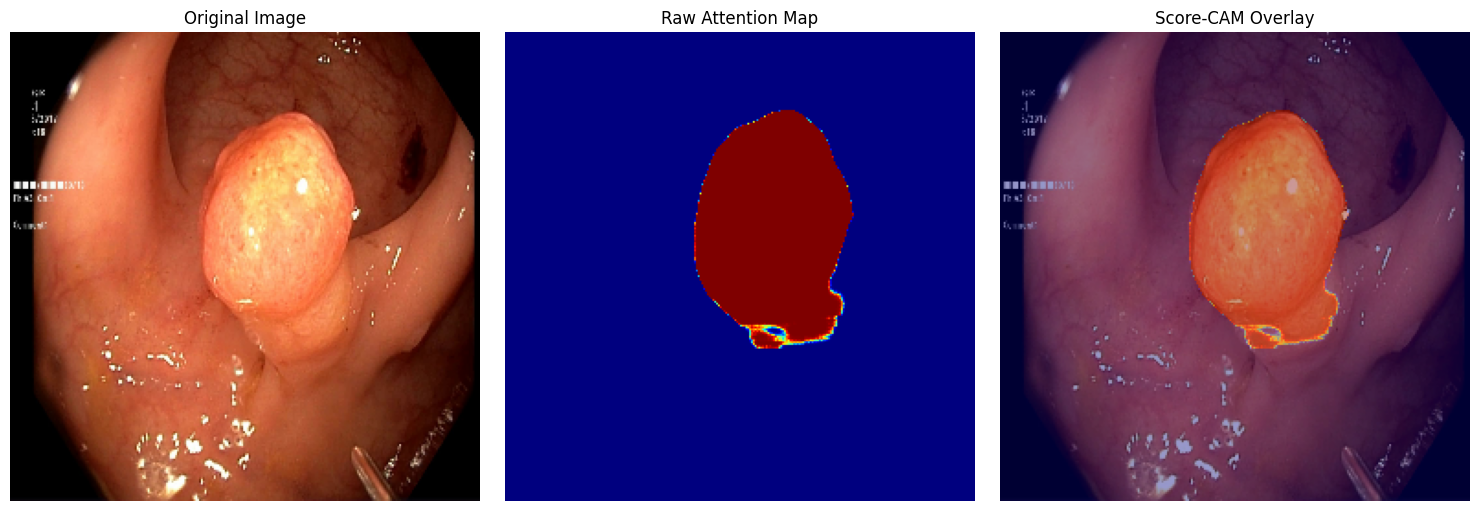

🏆 Score-CAM visualization compiled and saved cleanly at: ./score_cam_output/EndoCV2021_001304_score_cam.png
⏳ Loading trained model safely...
🧠 Computing Occlusion Sensitivity Map (this may take a moment)...


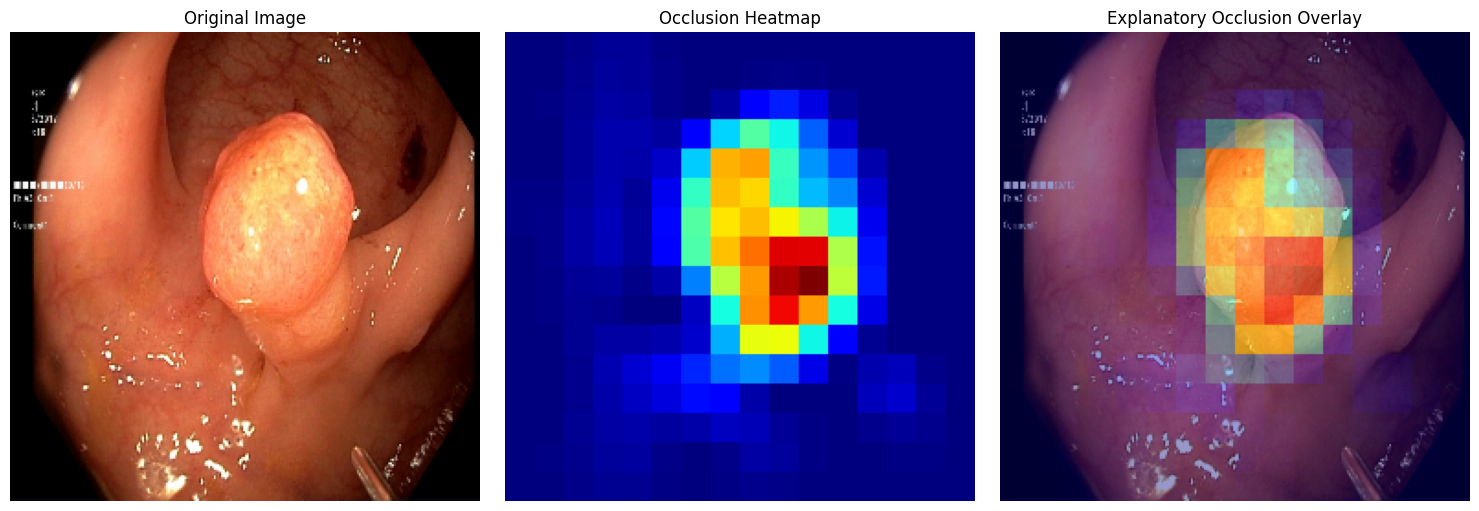

🏆 Visualization compiled and saved cleanly at: ./occlusion_output/EndoCV2021_001304_occlusion.png
⏳ Loading model and ELM artifacts...
✅ শেয়ার্ড hidden projection (shape (300, 1024)) + 4টা ridge-lambda output লোড হয়েছে।
🔎 Predicted polyp probability for this image: 2.0380
🚀 Running SHAP image explanation (max_evals=300)... this may take a bit.


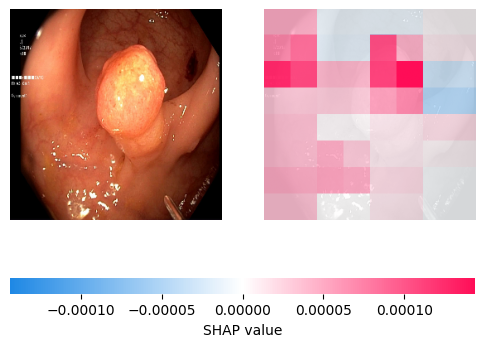

🖼️ Saved SHAP explanation plot to: shap_image_explanation_pos1.png
⏳ Loading model...

➔ [FORWARD TRACKING SUCCESS] Visualizing Frame ID: EndoCV2021_001304
🖼️ Saved to: ./feature_map_outputs/feature_map_EndoCV2021_001304.png


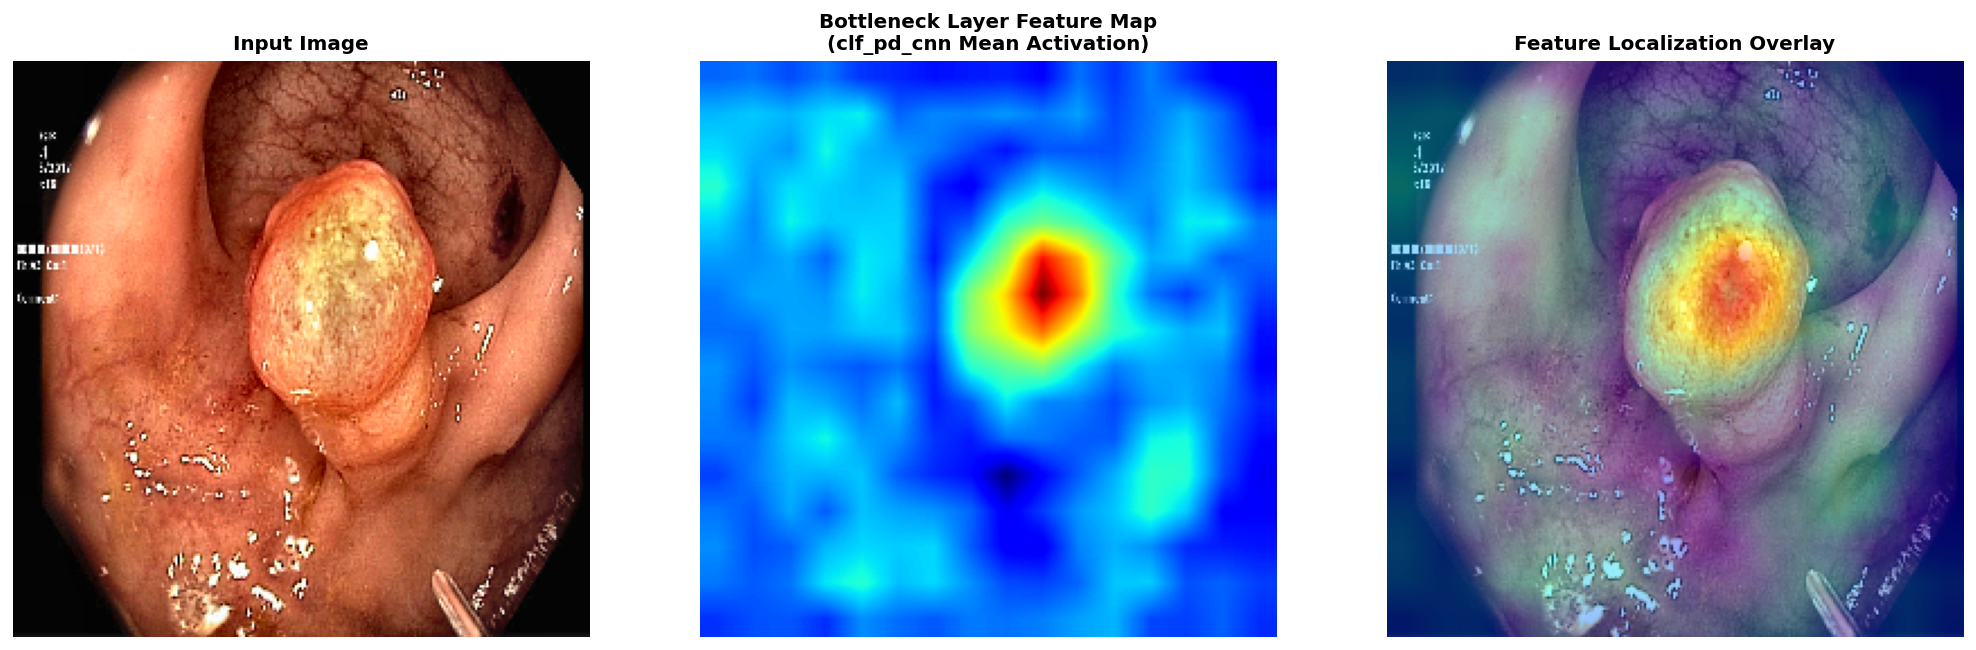

⏳ Loading model and ELM artifacts...
🚀 Computing SHAP tabular explanation (num_features=300, max_evals=601)...


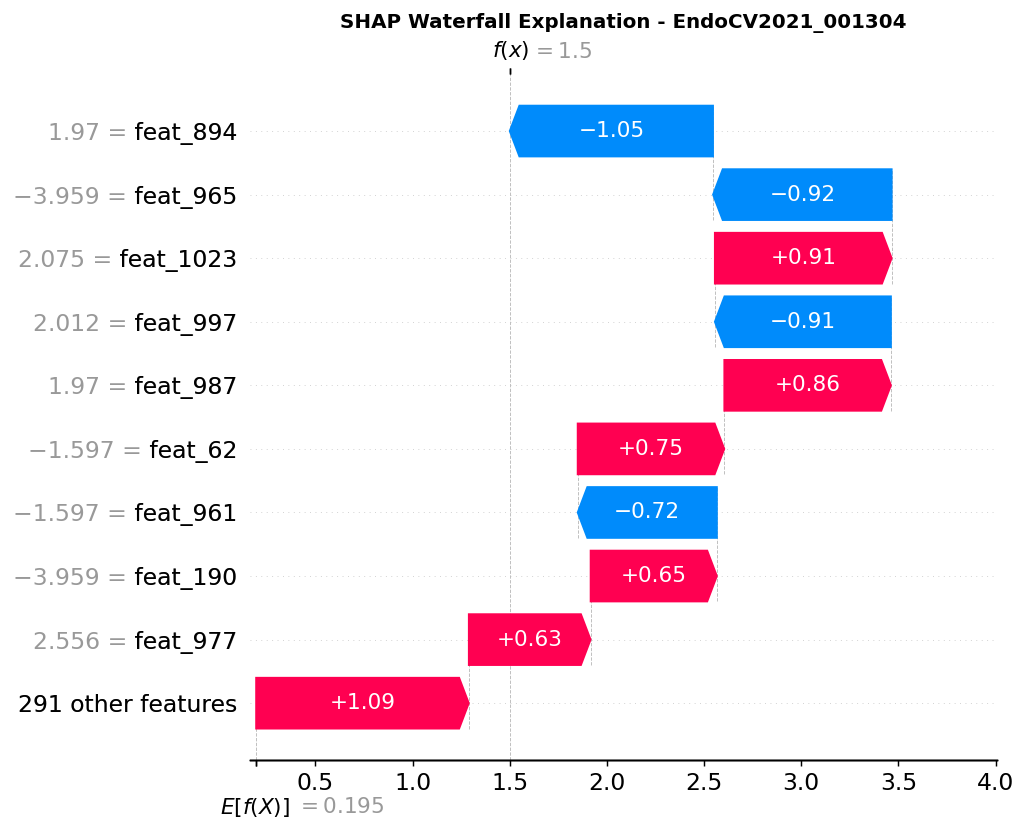

🖼️ Waterfall plot successfully saved to: shap_waterfall_sample_1.png


.values =
array([-1.28705253e-01,  7.30795925e-02, -2.65787427e-01,  2.81055954e-02,
       -8.85331256e-02, -9.62097150e-02, -7.73116081e-02,  2.26960751e-01,
        2.94774638e-01,  4.21731750e-01, -2.12676245e-01,  2.20921478e-02,
       -1.24689380e-01,  5.32035521e-02,  4.46460831e-03,  6.81473903e-03,
        7.54690589e-01,  8.00361026e-02,  1.16369798e-01, -1.55636783e-01,
        1.35245737e-01, -2.94919684e-01,  6.00673539e-02,  2.18631754e-01,
       -1.64521107e-03,  4.95241495e-02, -1.35423033e-01,  8.04616870e-02,
       -3.67570382e-02, -2.25537039e-02, -4.35196751e-01, -1.48611844e-01,
       -7.81193545e-02, -5.33928458e-02, -1.66647018e-02,  9.76645516e-02,
        3.44311315e-02,  7.61951589e-02, -7.23415715e-02,  4.35112598e-02,
        4.89684274e-02, -1.09860255e-04,  2.42358367e-01, -1.47762332e-01,
        1.04892231e-03,  1.86129319e-01,  1.30285731e-01, -2.33552784e-01,
       -2.65382987e-01,  3.23880085e-01, -8.43256168e-02, -6.16450497e-02,
       -1.98415

In [34]:
MODEL = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
IMAGE =  "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001304.jpg"
analyze_score_cam(image_path=IMAGE, model_path=MODEL)
analyze_occlusion_sensitivity(image_path=IMAGE, model_path=MODEL)
probability, shap_vals = generate_shap_explanation(
    image_path=IMAGE,
    model_path=MODEL_PATH,
    elm_artifact_path=ELM_ARTIFACT_PATH,
    output_png="shap_image_explanation_pos1.png",
    max_evals=300
)
output_png = generate_feature_map(
    image_path=IMAGE,
    model_path=MODEL,
    target_layer_name='clf_pd_cnn',
    output_dir="./feature_map_outputs"
)
generate_waterfall_plot(
    image_path=IMAGE,
    model_path=MODEL,
    elm_artifact_path=ELM_ARTIFACT,
    output_png="shap_waterfall_sample_1.png"
)